# Comparing three baseline churn models

Compare KNN, logistic regression and random forest with a majority-class
reference. These are baseline settings, before hyperparameter tuning.
Churn = 1 is the positive class. All results use five-fold stratified
cross-validation on the same 5,634 training customers, with shuffle enabled
and seed 42. The 1,409 final-test customers remain reserved.

The source is the [Kaggle Telco Customer Churn dataset](https://www.kaggle.com/datasets/blastchar/telco-customer-churn),
version 1, credited to IBM sample data. The first notebook records data quality
and exploration. Each model uses the same 19 predictors, excluding customerID
and Churn. SeniorCitizen stays categorical.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.models import make_models
from src.train import run_comparison, SCORING

## Baseline choices

KNN predicts from the five nearest training customers using Euclidean distance
and equal votes. Numeric scaling matters because distance depends on units.
Logistic regression estimates a churn probability using a linear combination
of encoded predictors, with L2 regularisation and C = 1. Random forest combines
100 decision trees and can capture non-linear relationships. Its numeric
predictors do not need standard scaling.

All pipelines impute numeric medians and one-hot encode categories. Medians,
scales and categories are learned separately inside each training fold.
Unseen validation categories are handled by the encoder. Prediction uses each
classifier's standard predict method; ROC-AUC uses its positive-class probability.
There is no threshold selection in this baseline comparison.

In [2]:
settings = pd.DataFrame([
    ["Majority reference", "Most frequent class", "Yes"],
    ["KNN", "5 neighbours; uniform votes; Euclidean distance; brute search", "Yes"],
    ["Logistic regression", "C=1; L2; lbfgs; max_iter=1000; tol=0.0001", "Yes"],
    ["Random forest", "100 trees; Gini; unlimited depth; sqrt features; bootstrap; seed=42", "No"],
], columns=["model", "baseline settings", "numeric scaling"])
display(settings)

,model,baseline settings,numeric scaling
0,Majority reference,Most frequent class,Yes
1,KNN,5 neighbours; uniform votes; Euclidean distanc...,Yes
2,Logistic regression,C=1; L2; lbfgs; max_iter=1000; tol=0.0001,Yes
3,Random forest,100 trees; Gini; unlimited depth; sqrt feature...,No


## Run the comparison

The runner creates one shared list of validation folds and evaluates each
complete preprocessing/classifier pipeline on that list. Each customer is
validated once. The fold results, summary and complete classifier settings
are saved under outputs/. Results are means across five validation folds;
standard deviations use the sample formula with ddof = 1. They describe
variation across these folds, not confidence intervals.

Churn F1 will be the primary score for the planned tuning phase because it
balances precision and recall in this imbalanced sample. This is a project
choice. Without actual intervention costs, no cost-optimal threshold or model
has been established. Keep accuracy, precision, recall and ROC-AUC visible.

In [3]:
fold_scores, summary = run_comparison()
assert len(fold_scores) == 20 and len(summary) == 4
assert fold_scores.groupby("model")["validation_rows"].sum().eq(5634).all()
display(summary.round(4))
display(fold_scores.round(4))

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Majority reference,0.7346,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000
1,KNN,0.7655,0.0055,0.5613,0.0102,0.5324,0.0237,0.5463,0.0157,0.7822,0.0058
2,Logistic regression,0.8026,0.0134,0.6547,0.0313,0.5431,0.0460,0.5930,0.0333,0.8461,0.0140
3,Random forest,0.7842,0.0104,0.6232,0.0299,0.4749,0.0289,0.5385,0.0228,0.8178,0.0126


,model,fold,training_rows,validation_rows,accuracy,precision,recall,f1,roc_auc
0,Majority reference,1,4507,1127,0.7347,0.0000,0.0000,0.0000,0.5000
1,Majority reference,2,4507,1127,0.7347,0.0000,0.0000,0.0000,0.5000
2,Majority reference,3,4507,1127,0.7347,0.0000,0.0000,0.0000,0.5000
3,Majority reference,4,4507,1127,0.7347,0.0000,0.0000,0.0000,0.5000
4,Majority reference,5,4508,1126,0.7345,0.0000,0.0000,0.0000,0.5000
5,KNN,1,4507,1127,0.7613,0.5528,0.5251,0.5386,0.7726
6,KNN,2,4507,1127,0.7640,0.5623,0.4983,0.5284,0.7845
7,KNN,3,4507,1127,0.7737,0.5753,0.5619,0.5685,0.7845
8,KNN,4,4507,1127,0.7604,0.5502,0.5318,0.5408,0.7815
9,KNN,5,4508,1126,0.7682,0.5660,0.5452,0.5554,0.7878


## Compare churn detection

Accuracy measures correct predictions overall. Precision measures the share
of predicted churners who actually churned; recall measures the share of actual
churners detected. F1 balances precision and recall. ROC-AUC measures probability
ranking over thresholds, so it answers a different question from F1 at the
classifier's prediction rule. Undefined churn precision/F1 is recorded as zero
for the majority reference, which predicts no churners.

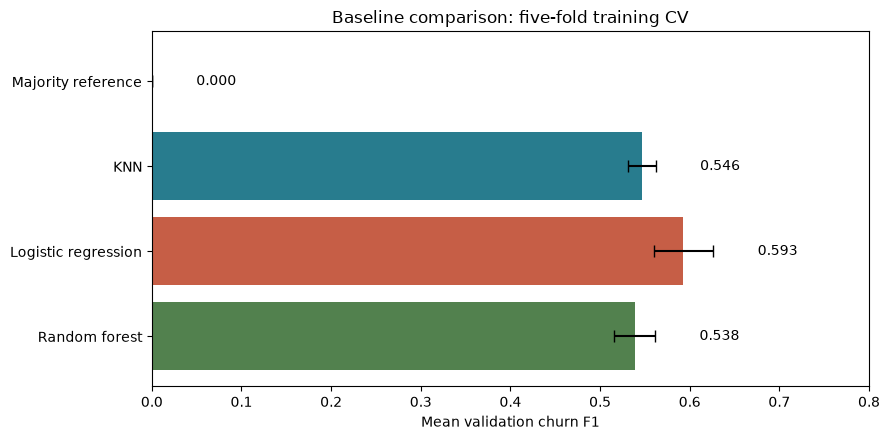

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(summary["model"], summary["f1_mean"], xerr=summary["f1_std"],
               color=["#999999", "#287C8E", "#C65E46", "#52814E"], capsize=4)
ax.bar_label(bars, labels=[f"{value:.3f}" for value in summary["f1_mean"]], padding=32)
ax.set(xlabel="Mean validation churn F1", xlim=(0, 0.8),
       title="Baseline comparison: five-fold training CV")
ax.invert_yaxis()
fig.tight_layout()
figure = ROOT / "outputs/figures/baseline_comparison.png"
figure.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure, dpi=160)
plt.show()
plt.close(fig)

Logistic regression has the highest mean F1 (0.5930), accuracy (0.8026) and
ROC-AUC (0.8461) among these baselines. Its mean precision is 0.6547 and recall
is 0.5431. KNN has mean F1 0.5463 and random forest 0.5385. These results
support taking logistic regression forward, while the planned tuning still
compares all three required models. They do not establish which tuned model
will perform best on the reserved test set.

The majority reference reaches 73.46% accuracy but has zero churn recall and
F1. All three baselines detect churners, although their mean recalls remain
below 0.55. Missing a churner means a possible retention opportunity is lost.
A false alarm could lead to unnecessary contact or an offer to a customer who
would have stayed. Actual costs and customer preferences are not available,
so these consequences have not been converted into monetary estimates.

The F1 error bars show one sample standard deviation across folds. Do not
treat this plot as a statistical significance test. Only one fixed split and
one CV seed have been examined, and these sample data do not establish
performance for a real provider. Fairness and final error analysis remain
later work. Both experimental settings in the brief still need clarification;
the planned baseline-versus-tuned interpretation is provisional.

Next planned phase: tune the three models using training CV and mean churn F1,
without consulting final-test results. OpenAI Codex assisted with code and
explanation drafts. The student should review and be able to explain the work.